# Importation des librairies

In [23]:
# Analyse de données

import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

# Préparation de données pour le machine learning

from sklearn.preprocessing import StandardScaler

# Modélisation et évaluation

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# EDA

In [24]:
# Chargement des données Uber de 2015

df_2015 = pd.read_csv("uber-raw-data-janjune-15.csv")

# Chargement du fichier de correspondance des zones

zone_lookup = pd.read_csv("taxi-zone-lookup.csv")

# Vérification des colonnes

print(df_2015.columns)
print(zone_lookup.columns)

Index(['Dispatching_base_num', 'Pickup_date', 'Affiliated_base_num',
       'locationID'],
      dtype='str')
Index(['LocationID', 'Borough', 'Zone'], dtype='str')


In [25]:
# Association de chaque locationID à sa zone et à son borough

df_2015 = df_2015.merge(
    zone_lookup[["LocationID", "Zone", "Borough"]],
    left_on="locationID",
    right_on="LocationID",
    how="left"
)

# Affichage des résultat

df_2015.head()

,Dispatching_base_num,Pickup_date,Affiliated_base_num,locationID,LocationID,Zone,Borough
0,B02617,2015-05-17 09:47:00,B02617,141,141,Lenox Hill West,Manhattan
1,B02617,2015-05-17 09:47:00,B02617,65,65,Downtown Brooklyn/MetroTech,Brooklyn
2,B02617,2015-05-17 09:47:00,B02617,100,100,Garment District,Manhattan
3,B02617,2015-05-17 09:47:00,B02774,80,80,East Williamsburg,Brooklyn
4,B02617,2015-05-17 09:47:00,B02617,90,90,Flatiron,Manhattan


In [26]:
df_2015.info()
df_2015.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 14270479 entries, 0 to 14270478
Data columns (total 7 columns):
 #   Column                Dtype
---  ------                -----
 0   Dispatching_base_num  str  
 1   Pickup_date           str  
 2   Affiliated_base_num   str  
 3   locationID            int64
 4   LocationID            int64
 5   Zone                  str  
 6   Borough               str  
dtypes: int64(2), str(5)
memory usage: 762.1 MB


,Dispatching_base_num,Pickup_date,Affiliated_base_num,locationID,LocationID,Zone,Borough
count,14270479,14270479,14108284,1.427048e+07,1.427048e+07,14270479,14270479
unique,8,2744783,284,NaN,NaN,260,7
top,B02764,2015-06-27 20:52:00,B02764,NaN,NaN,Midtown Center,Manhattan
freq,5753653,213,4352321,NaN,NaN,460732,10371060
mean,NaN,NaN,NaN,1.520574e+02,1.520574e+02,NaN,NaN
std,NaN,NaN,NaN,7.159620e+01,7.159620e+01,NaN,NaN
min,NaN,NaN,NaN,1.000000e+00,1.000000e+00,NaN,NaN
25%,NaN,NaN,NaN,9.200000e+01,9.200000e+01,NaN,NaN
50%,NaN,NaN,NaN,1.570000e+02,1.570000e+02,NaN,NaN
75%,NaN,NaN,NaN,2.300000e+02,2.300000e+02,NaN,NaN


In [27]:
# Vérification des valeurs manquantes dans le DataFrame

df_2015.isnull().sum()

Dispatching_base_num         0
Pickup_date                  0
Affiliated_base_num     162195
locationID                   0
LocationID                   0
Zone                         0
Borough                      0
dtype: int64

In [28]:
# Vérification des doublons dans le DataFrame

print(f"Nombre de doublons : {df_2015.duplicated().sum()}")
print(f"Le dataset contient {df_2015.duplicated().mean()*100:.2f}% doublons.")

Nombre de doublons : 898225
Le dataset contient 6.29% doublons.


# KMeans

In [29]:
# Calcul du nombre de courses par zone

demandes_zones = (
    df_2015.groupby(
        ["locationID", "Zone", "Borough"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "nb_courses"})
)

# Affichage du résultat

demandes_zones.head(10)

,locationID,Zone,Borough,nb_courses
0,1,Newark Airport,EWR,105
1,2,Jamaica Bay,Queens,8
2,3,Allerton/Pelham Gardens,Bronx,3684
3,4,Alphabet City,Manhattan,89319
4,5,Arden Heights,Staten Island,26
5,6,Arrochar/Fort Wadsworth,Staten Island,662
6,7,Astoria,Queens,90870
7,8,Astoria Park,Queens,369
8,9,Auburndale,Queens,3040
9,10,Baisley Park,Queens,6812


In [30]:
# Standardisation des valeurs numériques

# Définition des variables X

X = demandes_zones[["nb_courses"]]

# Initialisation de Standardscaler

scaler = StandardScaler()

# Application de Standardscaler sur la variable X

X_scaled = scaler.fit_transform(X)

# Initialisation du modèle KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=0,
)

# Application du modèle sur le dataset

demandes_zones["cluster"] = kmeans.fit_predict(X_scaled)

print(demandes_zones)

     locationID                     Zone        Borough  nb_courses  cluster
0             1           Newark Airport            EWR         105        0
1             2              Jamaica Bay         Queens           8        0
2             3  Allerton/Pelham Gardens          Bronx        3684        0
3             4            Alphabet City      Manhattan       89319        2
4             5            Arden Heights  Staten Island          26        0
..          ...                      ...            ...         ...      ...
257         261       World Trade Center      Manhattan       67904        0
258         262           Yorkville East      Manhattan      108338        2
259         263           Yorkville West      Manhattan      133630        2
260         264                  Unknown        Unknown           7        0
261         265                  Unknown        Unknown        6257        0

[262 rows x 5 columns]


## KMeans
### Méthode Elbow

In [31]:
# Calcul de l'inertie (WCSS) pour différentes valeurs de K, de 1 à 10,
# afin de déterminer le nombre optimal de clusters avec la méthode du coude

wcss = []
k = []

for i in range (1, 11) :
    kmeans= KMeans(n_clusters=i, random_state = 0, n_init='auto')
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
    k.append(i)
    print("WCSS pour K={} ---->{}".format(i, wcss[-1]))

WCSS pour K=1 ---->2180143419441.3628
WCSS pour K=2 ---->459240666343.83057
WCSS pour K=3 ---->213013292255.73355
WCSS pour K=4 ---->118164943532.71469
WCSS pour K=5 ---->59879278151.65158
WCSS pour K=6 ---->36345749351.24561
WCSS pour K=7 ---->29765324305.001446
WCSS pour K=8 ---->23101801875.388866
WCSS pour K=9 ---->17846969301.944515
WCSS pour K=10 ---->16398161334.76104


In [32]:
# Visualisation de l'inertie en fonction du nombre de clusters
# afin d'identifier le nombre optimal de clusters avec la méthode du coude

wcss_frame = pd.Series(wcss)
k_frame = pd.Series(k)

fig=px.line(
    x=k_frame,
    y=wcss_frame
)

fig.update_layout(
    yaxis_title="Inertia",
    xaxis_title="Clusters",
    title="Inertia per cluster"
)

fig.show()

## KMeans
### Méthode Silhouette

In [33]:
# Évaluation de la qualité du clustering avec la méthode silhouette
# pour différentes valeurs de K, de 2 à 10

sil = []
k = []

for i in range(2,11):
    kmeans = KMeans(n_clusters=i, random_state=0, n_init='auto')
    kmeans.fit(X)
    score = silhouette_score(X, kmeans.labels_,  sample_size=5000, random_state=0)
    sil.append(score)
    k.append(i)
    print(f"Silhouette score pour K={i} est : {score:.4f}")

Silhouette score pour K=2 est : 0.8136
Silhouette score pour K=3 est : 0.7691
Silhouette score pour K=4 est : 0.7696
Silhouette score pour K=5 est : 0.7611
Silhouette score pour K=6 est : 0.7649
Silhouette score pour K=7 est : 0.6458
Silhouette score pour K=8 est : 0.6264
Silhouette score pour K=9 est : 0.6202
Silhouette score pour K=10 est : 0.6001


In [34]:
# Visualisation des scores silhouette pour chaque valeur de K
# afin de comparer la qualité des clusters et d'identifier le nombre optimal de clusters

cluster_scores = pd.Series(sil)
k_frame = pd.Series(k)

fig=px.bar(x=k, y=cluster_scores)

fig.update_layout(
    yaxis_title="Silhouette Score",
    xaxis_title="# Clusters",
    title="Silhouette Score per cluster"
)

fig.show()

## Analyse des hot zones

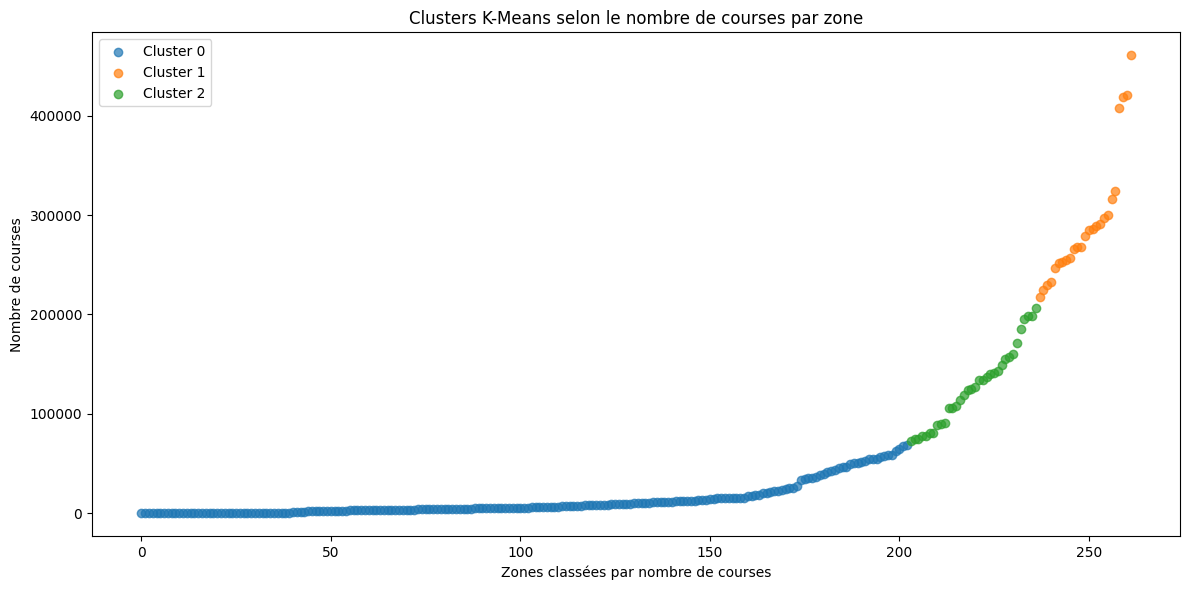

In [35]:
# Trie des zones selon leur demande

plot_df = demandes_zones.sort_values(
    "nb_courses"
).reset_index(drop=True)

# Visualisation des zones sous forme de points
    # L'axe X correspond au rang des zones après leur tri
    # L'axe Y représente le nombre de courses par zone
    # Une couleur différente identifie chaque cluster

plt.figure(figsize=(12, 6))

for cluster in sorted(plot_df["cluster"].unique()):
    subset = plot_df[plot_df["cluster"] == cluster]

    plt.scatter(
        subset.index,
        subset["nb_courses"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )


plt.title("Clusters K-Means selon le nombre de courses par zone")
plt.xlabel("Zones classées par nombre de courses")
plt.ylabel("Nombre de courses")
plt.legend()
plt.tight_layout()
plt.show()


Le clustering K-Means distingue trois groupes de zones selon leur nombre de courses : le cluster 0 regroupe les zones à faible demande, le cluster 2 les zones à demande intermédiaire et le cluster 1 les zones à forte demande. Le graphique met en évidence une forte concentration des courses dans un nombre limité de zones, tandis que la majorité enregistre des volumes plus faibles.

In [36]:
# Répartition des courses par Borought dans chaque cluster

courses_borough_cluster = demandes_zones.pivot_table(
    index="cluster",
    columns="Borough",
    values="nb_courses",
    aggfunc="sum",
    fill_value=0
)

display(courses_borough_cluster)

Borough,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island,Unknown
cluster,,,,,,,
0,220146,934691,105,798785,617267,6959,6264
1,0,217938,0,6569480,555288,0,0
2,0,1169371,0,3002795,171390,0,0


In [37]:
# Identification des Borought dominants dans chaque cluster

repartition_pct = (
    pd.crosstab(
        demandes_zones["cluster"],
        demandes_zones["Borough"],
        normalize="index"
    ) * 100
)

display(repartition_pct.round(1))

Borough,Bronx,Brooklyn,EWR,Manhattan,Queens,Staten Island,Unknown
cluster,,,,,,,
0,20.7,24.1,0.5,11.8,32.0,9.9,1.0
1,0.0,4.0,0.0,88.0,8.0,0.0,0.0
2,0.0,32.4,0.0,61.8,5.9,0.0,0.0


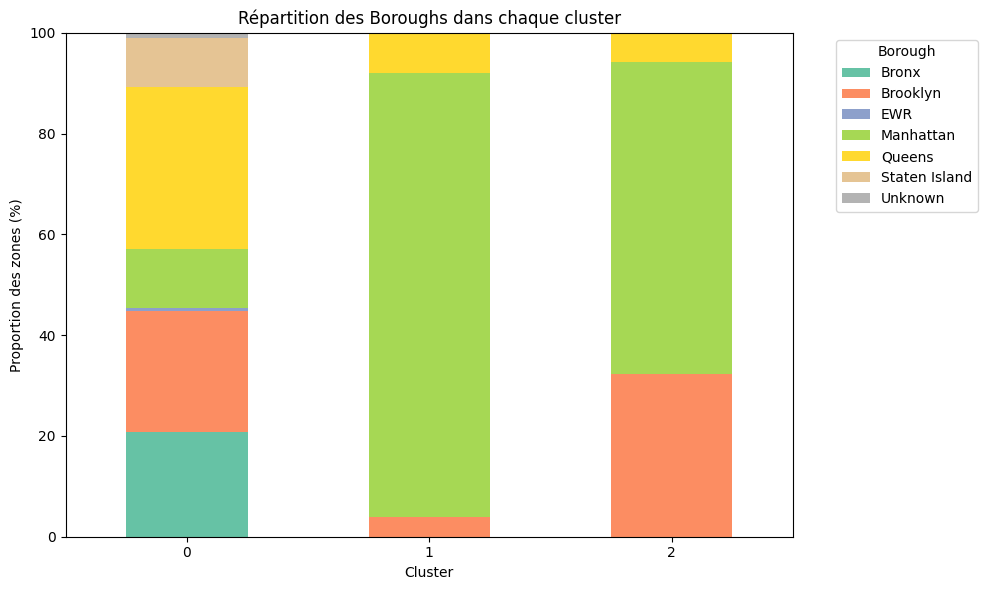

In [38]:
# Visualisation de la répartition des Borought dominants dans chaque cluster

# Calcule de la proportion des zones par Borough dans chaque cluster

repartition_pct = (
    pd.crosstab(
        demandes_zones["cluster"],
        demandes_zones["Borough"],
        normalize="index"
    ) * 100
)

repartition_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="Set2"
)

plt.title("Répartition des Boroughs dans chaque cluster")
plt.xlabel("Cluster")
plt.ylabel("Proportion des zones (%)")
plt.xticks(rotation=0)
plt.legend(title="Borough", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

Le graphique montre que le cluster 1 est très majoritairement composé de zones de Manhattan, tandis que le cluster 2 regroupe principalement Manhattan et Brooklyn. Le cluster 0 présente une répartition plus diversifiée, avec une forte présence de Brooklyn, du Queens et du Bronx. Cela suggère que les zones ayant des volumes de courses similaires se concentrent différemment selon les Boroughs, avec une prédominance de Manhattan dans les clusters 1 et 2.

In [39]:
# Calcul des zones les plus importantes de chaque cluster

for cluster in sorted(demandes_zones["cluster"].unique()):
    print(f"\nCluster {cluster} — Top 10 des zones")

    display(
        demandes_zones[
            demandes_zones["cluster"] == cluster
        ][["Zone", "Borough", "nb_courses"]]
        .sort_values("nb_courses", ascending=False)
        .head(10)
    )


Cluster 0 — Top 10 des zones


,Zone,Borough,nb_courses
24,Boerum Hill,Brooklyn,69154
257,World Trade Center,Manhattan,67904
40,Central Harlem,Manhattan,64767
41,Central Harlem North,Manhattan,63011
221,Stuyvesant Heights,Brooklyn,59136
148,Manhattan Valley,Manhattan,58730
87,Financial District South,Manhattan,57803
163,Morningside Heights,Manhattan,56475
186,Prospect Heights,Brooklyn,54928
222,Sunnyside,Queens,54830



Cluster 1 — Top 10 des zones


,Zone,Borough,nb_courses
158,Midtown Center,Manhattan,460732
227,TriBeCa/Civic Center,Manhattan,420356
230,Union Sq,Manhattan,419045
78,East Village,Manhattan,407591
245,West Village,Manhattan,323989
226,Times Sq/Theatre District,Manhattan,315919
67,East Chelsea,Manhattan,299781
160,Midtown North,Manhattan,296734
167,Murray Hill,Manhattan,290550
129,JFK Airport,Queens,289169



Cluster 2 — Top 10 des zones


,Zone,Borough,nb_courses
111,Greenwich Village South,Manhattan,206420
138,Lenox Hill West,Manhattan,198226
139,Lincoln Square East,Manhattan,198052
183,Penn Station/Madison Sq West,Manhattan,195698
235,Upper West Side South,Manhattan,185741
225,Sutton Place/Turtle Bay North,Manhattan,171662
178,Park Slope,Brooklyn,160037
99,Garment District,Manhattan,157241
86,Financial District North,Manhattan,154994
49,Clinton West,Manhattan,149228


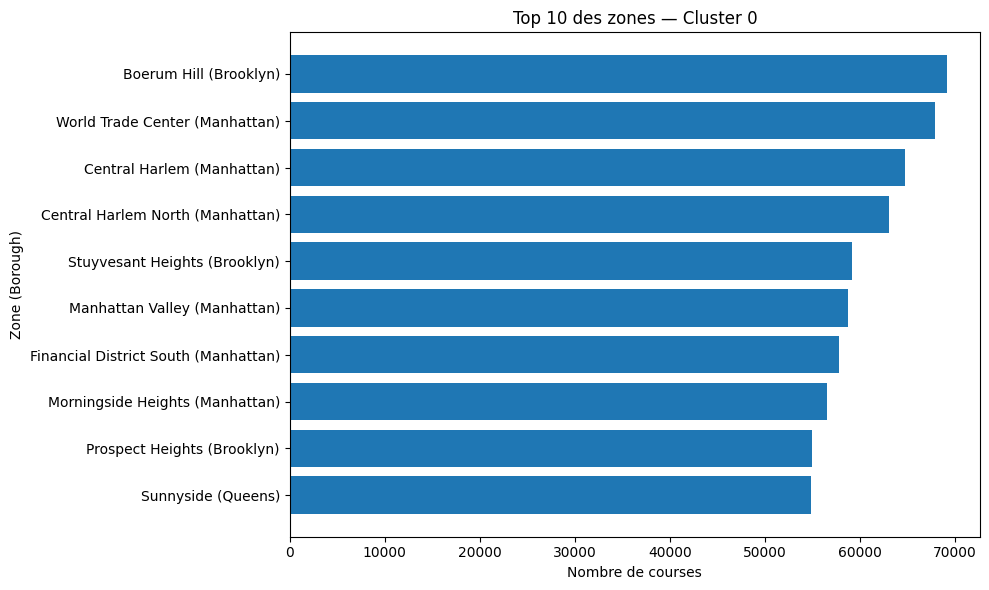

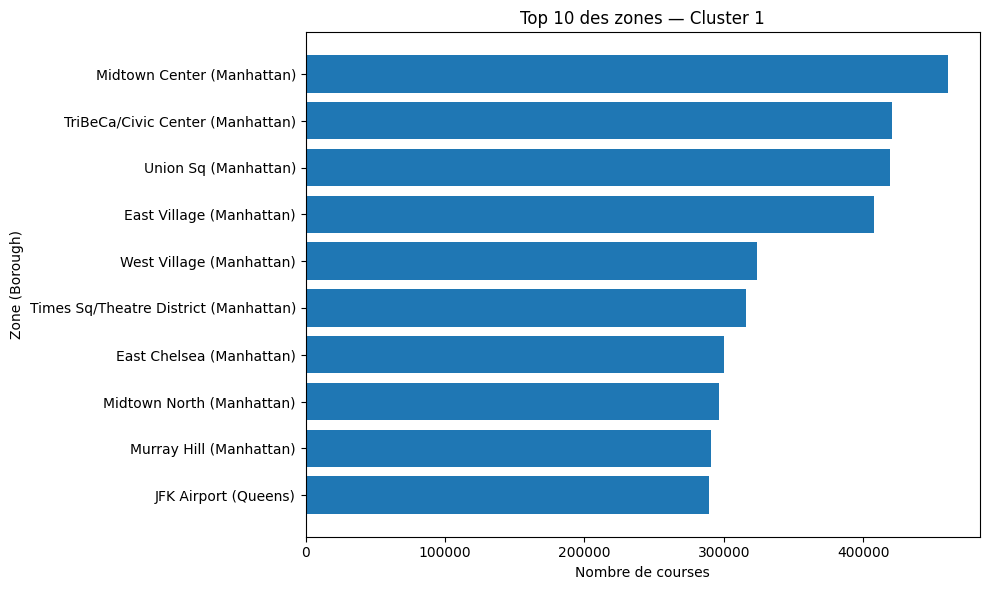

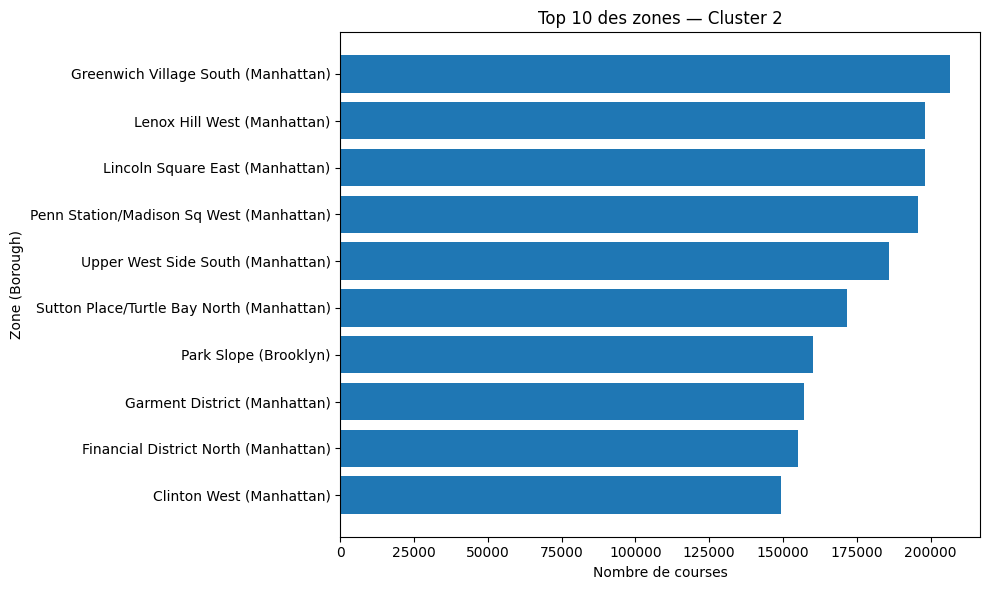

In [40]:
# Création d'un graphique pour chaque cluster

for cluster in sorted(demandes_zones["cluster"].unique()):

    # Sélection des 10 zones ayant le plus de courses
    
    top_zones = (
        demandes_zones[demandes_zones["cluster"] == cluster]
        .nlargest(10, "nb_courses")
        .sort_values("nb_courses", ascending=True)
    )

    # Création du graphique
    
    plt.figure(figsize=(10, 6))

    plt.barh(
        top_zones["Zone"] + " (" + top_zones["Borough"] + ")",
        top_zones["nb_courses"]
    )

    plt.title(f"Top 10 des zones — Cluster {cluster}")
    plt.xlabel("Nombre de courses")
    plt.ylabel("Zone (Borough)")
    plt.tight_layout()
    plt.show()

In [41]:
# Association des clusters aux zones

df_2015 = df_2015.merge(
    demandes_zones[["locationID", "cluster"]],
    on="locationID",
    how="left"
)

In [51]:
# Conversion de la colonne Date/Time en datetime

df_2015["Pickup_date"] = pd.to_datetime(df_2015["Pickup_date"])

# Extraction du jour de la semaine

df_2015['Day_of_week'] = (df_2015["Pickup_date"].dt.day_name()
)

# Extraction de l'heure

df_2015['Hour'] = df_2015["Pickup_date"].dt.hour

df_2015.head()

,Dispatching_base_num,Pickup_date,Affiliated_base_num,locationID,LocationID,Zone,Borough,cluster,Day_of_week,Hour
0,B02617,2015-05-17 09:47:00,B02617,141,141,Lenox Hill West,Manhattan,2,Sunday,9
1,B02617,2015-05-17 09:47:00,B02617,65,65,Downtown Brooklyn/MetroTech,Brooklyn,0,Sunday,9
2,B02617,2015-05-17 09:47:00,B02617,100,100,Garment District,Manhattan,2,Sunday,9
3,B02617,2015-05-17 09:47:00,B02774,80,80,East Williamsburg,Brooklyn,2,Sunday,9
4,B02617,2015-05-17 09:47:00,B02617,90,90,Flatiron,Manhattan,1,Sunday,9


In [52]:
# Analyse des jours les plus demandés par cluster 
# Création d'un tableau croisé indiquant le nombre de prises en charge pour chaque combinaison de cluster et de jour de la semaine

demand_by_cluster = pd.crosstab(
    df_2015["cluster"],
    df_2015["Day_of_week"]
)

# Définition de l'ordre chronologique des jours de la semaine

days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Réorganisation des colonnes selon l'ordre des jours
# et ajout d'une valeur 0 si un jour est absent des données

demand_by_cluster = demand_by_cluster.reindex(columns=days_order, fill_value=0)

print(demand_by_cluster)

# Identification du jour qui compte le plus de prises en charge
# pour chaque cluster

most_demanded_day = demand_by_cluster.idxmax(axis=1)

# Création d'un tableau récapitulatif

summary = pd.DataFrame({
    "Most demanded day": most_demanded_day,
    "Number of pickups": demand_by_cluster.max(axis=1)
})

print(summary)

Day_of_week  Monday  Tuesday  Wednesday  Thursday   Friday  Saturday  Sunday
cluster                                                                     
0            310380   315729     316670    351985   402882    479703  406868
1            876396  1009421    1021421   1176728  1181094   1149354  928292
2            507476   547752     555720    630885   698595    785506  617622
        Most demanded day  Number of pickups
cluster                                     
0                Saturday             479703
1                  Friday            1181094
2                Saturday             785506


In [54]:
# Visualisation du nombre de prises en charge par jour et par cluster
# à l'aide d'une heatmap

fig = px.imshow(
    demand_by_cluster,
    labels={
        "x": "Day of week",
        "y": "Cluster",
        "color": "Number of pickups"
    },
    x=demand_by_cluster.columns,
    y=demand_by_cluster.index,
    color_continuous_scale="YlOrRd",
    text_auto=True,
    aspect="auto",
    title="Weekly Pickup Demand by Cluster"
)

fig.show()

Le cluster 1 concentre globalement le plus grand volume de courses, notamment du jeudi au samedi, tandis que le cluster 0 présente les volumes les plus faibles. Le samedi est le jour particulièrement actif pour les trois clusters.


In [55]:
# Calcule du nombre de courses pour chaque combinaison de cluster et d'heure

courses_heure_cluster = (
    df_2015
    .groupby(["cluster", "Hour"])
    .size()
    .unstack(fill_value=0)
)

display(courses_heure_cluster)

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cluster,,,,,,,,,,,,,,,,,,,,,
0,102464,72033,48573,37929,41738,49643,72629,107317,127456,118143,...,114432,119764,126495,140938,152399,153734,148909,148259,146344,132106
1,327320,207773,136485,92690,76338,77086,113727,174889,238087,258558,...,297896,342324,400631,476311,548993,558493,528055,521510,514633,449261
2,172394,114704,75545,53036,54962,66794,102177,161337,217805,216736,...,172135,187326,210044,246741,285701,295237,271610,260693,261977,233422


In [56]:
# Visualisation des heures de pointe par cluster à l'aide d'une heatmap

fig = px.imshow(
    courses_heure_cluster,
    labels={
        "x": "Hour of day",
        "y": "Cluster",
        "color": "Number of pickups"
    },
    x=courses_heure_cluster.columns,
    y=courses_heure_cluster.index,
    color_continuous_scale="YlOrRd",
    aspect="auto",
    title="Hourly Pickup Demand by Cluster"
)

fig.update_layout(
    xaxis=dict(
        tickmode="linear",
        dtick=1
    )
)

fig.show()

La heatmap montre que le cluster 1 connaît la demande la plus élevée en soirée, avec un pic particulièrement marqué entre 18 h et 22 h, autour de 19 h. Les trois clusters présentent une baisse d’activité pendant la nuit et au petit matin, puis une reprise progressive dans la journée. Le cluster 2 connaît également une hausse en soirée, mais plus modérée, tandis que le cluster 0 conserve un volume relativement stable. Ces résultats soulignent l’importance de la période du soir, notamment pour les zones du cluster 1.

In [57]:
# Calcul du nombre de courses par cluster, jour et heure

demand = (
    df_2015
    .groupby(["cluster", "Day_of_week", "Hour"])
    .size()
    .reset_index(name="Number of pickups")
)

# Identification de l'heure de pointe pour chaque cluster et chaque jour

idx = (
    demand
    .groupby(["cluster", "Day_of_week"])["Number of pickups"]
    .idxmax()
)

peak_hours = demand.loc[idx].copy()

# Définition de l'ordre chronologique des jours

days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

peak_hours["Day_of_week"] = pd.Categorical(
    peak_hours["Day_of_week"],
    categories=days_order,
    ordered=True
)

# Trie par cluster et par jour

peak_hours = peak_hours.sort_values(
    ["cluster", "Day_of_week"]
)

# Affichage des résultat

display(peak_hours)

,cluster,Day_of_week,Hour,Number of pickups
32,0,Monday,8,20071
128,0,Tuesday,8,20899
152,0,Wednesday,8,20826
104,0,Thursday,8,21440
23,0,Friday,23,27440
70,0,Saturday,22,31685
72,0,Sunday,0,26943
210,1,Monday,18,67969
306,1,Tuesday,18,86619
331,1,Wednesday,19,85336


In [58]:
# Visualisation des heures de pointe par cluster à l'aide d'une heatmap

peak_matrix = (
    peak_hours
    .pivot(
        index="Day_of_week",
        columns="cluster",
        values="Hour"
    )
    .reindex(days_order)
)


fig = px.imshow(
    peak_matrix,
    labels={
        "x": "Cluster",
        "y": "Jour de la semaine",
        "color": "Heure de pointe"
    },
    x=[f"Cluster {c}" for c in peak_matrix.columns],
    y=peak_matrix.index,
    color_continuous_scale="Turbo",
    text_auto=True,
    aspect="auto",
    title="Heures de pointe par cluster et par jour"
)

fig.update_layout(
    xaxis_title="Cluster",
    yaxis_title="Jour de la semaine"
)

fig.show()

La heatmap montre que les heures de pointe varient selon le cluster et le jour de la semaine. Le cluster 1 présente des pics en soirée, généralement entre 18 h et 21 h, avec un maximum à 23 h le samedi. Le cluster 2 atteint principalement son pic autour de 19 h du mardi au samedi, tandis que le cluster 0 connaît des pics plus tardifs le vendredi à 23 h et le samedi à 22 h.

# Conclusion

L’analyse des données Uber de janvier à juin 2015 met en évidence trois principaux pôles de demande : Manhattan, Brooklyn et Queens, avec une activité particulièrement importante en fin d’après-midi et en soirée.

L’analyse par clustering permet d’affiner ces observations : 

Le cluster 0, principalement répartie entre Queens, Brooklyn et Bronx : le jour le plus demandé est le samedi -> Renforcer la disponibilité le vendredi et le samedi, notamment vers 22 h et 23 h, et vers 8h du lundi au jeudi.

Le cluster 1, dominé par Manhattan, le jour le plus demandé est le vendredi -> Prévoir une couverture tardive, avec des pics hebdomadaires entre 18 h et 23 h.

Le cluster 2, également caractérisé par une forte présence de zones de Manhattan mais également Brooklyn, le jour le plus demandé est le samedi -> Renforcer la disponibilité autour de 18 h et 19 h, du mardi au samedi, et vers 8h le lundi.

Ces résultats confirment le rôle central de Manhattan dans la demande Uber, tout en soulignant l’importance de Brooklyn et de Queens.
